##### __Датасет частин 1-2__: "Web page Phishing Detection Dataset"
##### __Посилання на датасет__: https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset
##### __Опис датасету__: 11 430 URL-адрес із 87 ознаками: 56 отримано зі структури та синтаксису URL, 24 зі змісту сторінок і 7 із запитів до зовнішніх сервісів. Датасет збалансований: рівно 50% фішингових і 50% легітимних адрес.

##### __Датасет частини 3__: "MovieLens Latest Datasets" (ml-latest-small)
##### __Посилання на датасет__: https://grouplens.org/datasets/movielens/latest/
##### __Опис датасету__: оцінки та текстові теги, які користувачі сервісу MovieLens ставили фільмам: 100 836 оцінок і 3 683 застосування тегів до 9 742 фільмів (610 користувачів, дані за 1996-2018 роки). Для класифікації тексту використано два файли: `tags.csv` (теги користувачів, які є нашими текстами) та `movies.csv` (жанри фільмів, які є нашими класами).

In [3]:
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import silhouette_score, adjusted_rand_score

Зниження розмірності та візуалізація

Мета частини: застосувати PCA для зменшення кількості ознак, порівняти якість Random Forest до і після PCA, а також візуалізувати дані в 2D за допомогою t-SNE.

##### Завантаження і первинний аналіз

In [4]:
df = pd.read_csv('../lab1/dataset_phishing.csv')
print(df.shape)
print(df['status'].value_counts())
print(df.isnull().sum().sum())

(11430, 89)
status
legitimate    5715
phishing      5715
Name: count, dtype: int64
0


In [5]:
y = df['status'].map({'legitimate': 0, 'phishing': 1})
X = df.drop(['url', 'status'], axis=1)
print(X.shape)

(11430, 87)


##### Задача, ознаки та цільова змінна

Задача та сама, що й у лабораторній роботі 1: за характеристиками веб-сторінки визначити, чи вона легітимна, чи фішингова (бінарна класифікація). Датасет має 11 430 об'єктів і 87 числових ознак, пропущених значень немає (вивід `0`), класи збалансовані (по 5 715 об'єктів), тому accuracy є коректною метрикою.

Колонку `url` вилучено, оскільки це унікальний текстовий ідентифікатор, а не ознака. Цільову змінну `status` закодовано вручну: `legitimate` = 0, `phishing` = 1 (так само, як і в лабораторній роботі 1). Фішинг є «позитивним» класом.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

##### Розбиття вибірки та масштабування

Вибірку розбито на навчальну та тестову у співвідношенні 70/30 (8 001 і 3 429 об'єктів) із параметром `stratify=y`, який зберігає баланс класів в обох частинах. `random_state=10` забезпечує відтворюваність результатів.

Ознаки стандартизовано за допомогою `StandardScaler` (середнє 0, стандартне відхилення 1). PCA і K-Means залежать від дисперсії та відстаней, тому без масштабування ознаки з великими значеннями (наприклад, `web_traffic`) повністю домінували б над рештою. Для Random Forest масштабування не потрібне, але щоб порівняння «до» і «після» PCA було коректним, обидві моделі навчаються на однаково масштабованих даних. Параметри масштабування (`fit`) обчислюються лише за навчальною вибіркою, а до тестової застосовується лише `transform`, щоб не було витоку даних (data leakage).

In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=10)

start = time.time()
rf.fit(X_train_scaled, y_train)
time_before = time.time() - start

y_pred = rf.predict(X_test_scaled)
acc_before = accuracy_score(y_test, y_pred)
f1_before = f1_score(y_test, y_pred)

print('Ознак:', X_train_scaled.shape[1])
print('Accuracy:', acc_before)
print('F1:', f1_before)
print('Час навчання:', time_before)

Ознак: 87
Accuracy: 0.9612131816856226
F1: 0.9611451942740287
Час навчання: 0.4680449962615967


##### Random Forest до PCA (базова модель)

Random Forest зі 100 дерев навчено на всіх 87 ознаках. Це базовий результат, із яким порівнюється модель після PCA: accuracy 0.961, F1 0.961, час навчання 0.46 с.

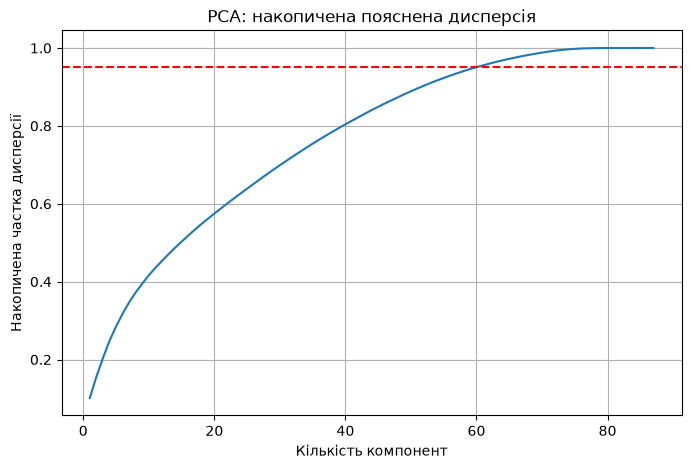

In [8]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative)
plt.axhline(0.95, color='red', linestyle='--')
plt.xlabel('Кількість компонент')
plt.ylabel('Накопичена частка дисперсії')
plt.title('PCA: накопичена пояснена дисперсія')
plt.grid()
plt.show()

##### Вибір кількості головних компонент

На графіку показано накопичену частку дисперсії, яку пояснюють перші k головних компонент. Крива зростає поступово: перша компонента пояснює близько 10% дисперсії, 80% досягається приблизно на 40 компонентах, а поріг 95% (червона лінія) перетинається на 60-й компоненті. Отже, ознаки дублюють одна одну лише частково (у лабораторній роботі 1 ми бачили сильну кореляцію тільки між окремими ознаками, наприклад `ip` та `ratio_digits_url`, 0.77), і значно стиснути дані без втрати інформації не вдається.

Для моделей машинного навчання зазвичай залишають стільки компонент, щоб зберегти близько 95% дисперсії (Лекція 4). Тому в `PCA` задано `n_components=0.95`: бібліотека сама підбирає мінімальну кількість компонент, яка дає таку частку.

In [9]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print('Було ознак:', X_train_scaled.shape[1])
print('Стало компонент:', X_train_pca.shape[1])
print('Збережена дисперсія:', pca.explained_variance_ratio_.sum())

rf_pca = RandomForestClassifier(n_estimators=100, random_state=10)

start = time.time()
rf_pca.fit(X_train_pca, y_train)
time_after = time.time() - start

y_pred_pca = rf_pca.predict(X_test_pca)
acc_after = accuracy_score(y_test, y_pred_pca)
f1_after = f1_score(y_test, y_pred_pca)

results = pd.DataFrame({
    'Модель': ['RF без PCA', 'RF після PCA'],
    'Ознак': [X_train_scaled.shape[1], X_train_pca.shape[1]],
    'Accuracy': [acc_before, acc_after],
    'F1': [f1_before, f1_after],
    'Час навчання, с': [time_before, time_after]
})
print(results)

Було ознак: 87
Стало компонент: 60
Збережена дисперсія: 0.95088878105097
         Модель  Ознак  Accuracy        F1  Час навчання, с
0    RF без PCA     87  0.961213  0.961145         0.468045
1  RF після PCA     60  0.942840  0.943188         1.735138


##### Результати Random Forest до та після PCA

| | Без PCA | Після PCA |
|---|---|---|
| Кількість ознак | 87 | 60 |
| Збережена дисперсія | 100% | 95.1% |
| Accuracy | 0.961 | 0.943 |
| F1 | 0.961 | 0.943 |
| Час навчання, с | 0.47 | 1.74 |

Висновки:

1. Кількість ознак. PCA зменшила кількість ознак із 87 до 60 (на 31%), зберігши 95.1% дисперсії.
2. Якість. Accuracy та F1 зменшилися приблизно на 1.8 в.п. (з 0.961 до 0.943). Втрата невелика, але PCA не покращила класифікацію. Причина в тому, що PCA не знає про цільову змінну: вона зберігає напрямки з найбільшим розкидом об'єктів, а не ті, що найкраще розділяють класи. Інформація, важлива для розділення класів (у лабораторній роботі 1 найважливішими були `google_index` та `page_rank`), може міститися у відкинутих 5% дисперсії.
3. Час навчання. Він не зменшився, а збільшився приблизно у 3.6 раза (з 0.47 до 1.74 с). Компоненти PCA є неперервними лінійними комбінаціями всіх 87 ознак, тому для дерева кожен поділ має значно більше можливих порогів, ніж для вихідних ознак, серед яких багато бінарних і цілочисельних. Зменшення кількості ознак із 87 до 60 цього не компенсувало. Абсолютний час залежить від комп'ютера й конкретного запуску, але співвідношення між моделями зберігається.

Загальний висновок: для цього датасету та цієї моделі PCA як крок попередньої обробки перед Random Forest недоцільна. Random Forest добре працює з вихідними ознаками й не потребує ні масштабування, ні зниження розмірності. PCA корисніша для візуалізації та для моделей, чутливих до кількості ознак і мультиколінеарності (наприклад, kNN або лінійні моделі).

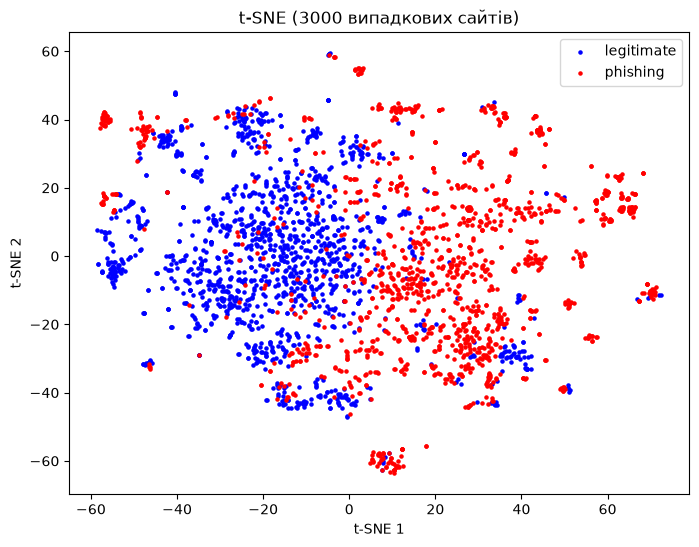

In [10]:
X_scaled = StandardScaler().fit_transform(X)

sample_index = X.sample(n=3000, random_state=10).index
X_sample = X_scaled[sample_index]
y_sample = y[sample_index].values

tsne = TSNE(n_components=2, perplexity=30, random_state=10)
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[y_sample == 0, 0], X_tsne[y_sample == 0, 1], s=5, color='blue', label='legitimate')
plt.scatter(X_tsne[y_sample == 1, 0], X_tsne[y_sample == 1, 1], s=5, color='red', label='phishing')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE (3000 випадкових сайтів)')
plt.legend()
plt.show()

##### t-SNE: візуалізація в 2D

t-SNE (t-distributed Stochastic Neighbor Embedding) розміщує об'єкти на площині так, щоб ті, що були близькими в 87-вимірному просторі, залишилися близькими й у 2D. Тобто він зберігає локальних сусідів, на відміну від PCA, який зберігає напрямки максимальної дисперсії. Алгоритм повільний і випадковий, тому для швидкості та читабельності взято випадкову підвибірку з 3 000 сайтів, `perplexity=30` (орієнтовна кількість сусідів, яку враховує кожна точка) і `random_state=10`. Дані попередньо стандартизовано. Мітки класів алгоритм не використовує, вони потрібні лише для розфарбування точок.

Результат:

1. Легітимні (сині) та фішингові (червоні) сайти займають помітно різні області: сині переважно ліворуч, червоні праворуч. Тобто класи справді відрізняються за сукупністю ознак, що узгоджується з високою точністю Random Forest (понад 96%).
2. У центральній частині є широка зона перемішування: там сайти одного класу схожі за ознаками на сайти іншого. Ймовірно, саме такі сайти найскладніші для класифікатора, а ідеально розділити класи двома координатами не вдається.
3. Є невеликі щільні «острівці» (наприклад, групи червоних точок у лівій верхній частині та внизу): це групи дуже схожих між собою сайтів, імовірно створених за одним шаблоном. Частина червоних острівців лежить усередині «синьої» області, тобто такі фішингові сайти за ознаками схожі на легітимні й їх найважче виявити. Є й невеликі сині острівці всередині червоної області.
4. Осі t-SNE не мають змісту, а відстані між віддаленими групами та розміри груп інтерпретувати не можна. t-SNE придатний саме для візуалізації, а не як крок попередньої обробки для моделі (нові точки він перетворити не може).

##### Частина 2. Кластерний аналіз

Кластеризація належить до навчання без вчителя: алгоритм має знайти групи схожих об'єктів, не використовуючи мітки класів. Тому для K-Means використано лише стандартизовані ознаки `X_scaled`, а колонка `status` застосовується тільки наприкінці для порівняння знайдених кластерів зі справжніми класами. Датасет має лише 2 класи, тому скорочувати їхню кількість не потрібно.

[925830.0000000001, 868073.3790466653, 836455.1726299492, 813790.3964965319, 788724.9507140326, 769946.1352246904, 749684.7806150512, 737225.0270763519, 717831.8520183761, 704167.3210779083]
[0.3282836886816733, 0.06477063345559612, 0.05637446991463029, 0.07121999031138128, 0.06450961442365055, 0.06700293896643329, 0.07029479029178491, 0.07640520278173255, 0.08447107846162133]


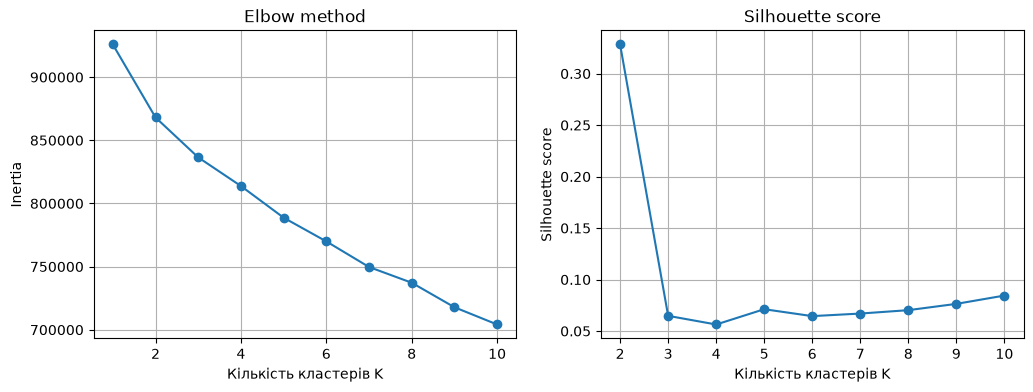

In [11]:
k_values = range(1, 11)
inertia_list = []
silhouette_list = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=10, n_init=10)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)
    if k > 1:
        silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))

print(inertia_list)
print(silhouette_list)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_list, marker='o')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), silhouette_list, marker='o')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Silhouette score')
plt.title('Silhouette score')
plt.grid()

plt.show()

##### Вибір кількості кластерів: Elbow Method

K-Means розбиває дані на K кластерів, мінімізуючи inertia (суму квадратів відстаней від об'єктів до центрів їхніх кластерів). Inertia завжди зменшується зі зростанням K, тому за методом ліктя шукають значення K, після якого зменшення помітно сповільнюється. Для підтвердження вибору додатково обчислено silhouette score (від −1 до 1: наскільки об'єкт ближчий до свого кластера, ніж до чужих; Лекція 4). Параметр `n_init=10` означає, що алгоритм запускається 10 разів із різними початковими центрами й обирається найкращий результат.

Результати:

1. Elbow. Inertia плавно зменшується з 925 830 (K=1) до 704 167 (K=10), загалом лише на 24%. Найбільше падіння відбувається між K=1 і K=2 (на 57 757, тобто 6.2%), далі кожен крок дає 12–32 тисячі без чіткого «ліктя». Тобто виразної кластерної структури в даних немає.
2. Silhouette. Для K=2 значення становить 0.33, а для всіх K від 3 до 10 лише 0.06–0.08, тобто за більшої кількості кластерів вони сильно перекриваються.

Обрано K = 2: найбільше падіння inertia та значно вищий silhouette.

Дисперсія двох компонент: 0.15507701974956692


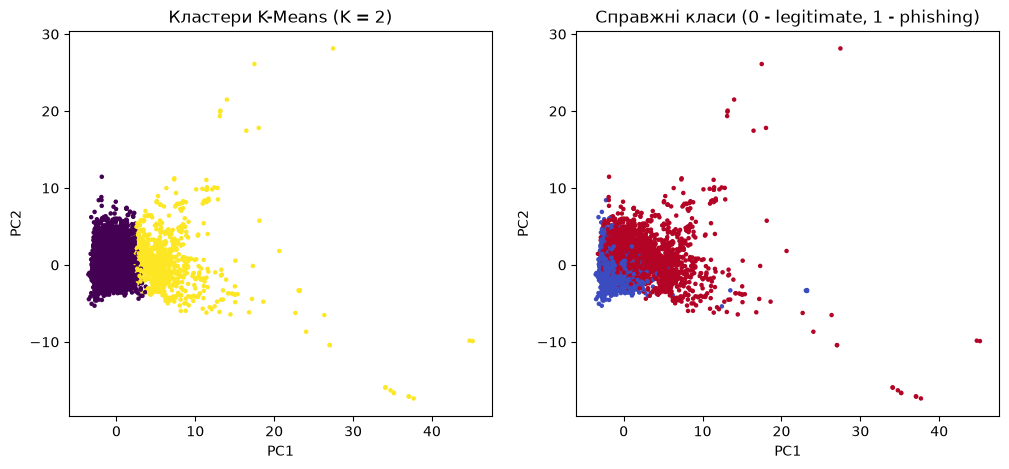

In [12]:
kmeans = KMeans(n_clusters=2, random_state=10, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print('Дисперсія двох компонент:', pca_2d.explained_variance_ratio_.sum())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=clusters, s=5, cmap='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Кластери K-Means (K = 2)')

plt.subplot(1, 2, 2)
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, s=5, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Справжні класи (0 - legitimate, 1 - phishing)')

plt.show()

##### Візуалізація кластерів у 2D за допомогою PCA

K-Means виконано на всіх 87 стандартизованих ознаках, а PCA з двома компонентами використано лише для малювання. Дві компоненти пояснюють лише 15.5% дисперсії, тому 2D-картинка є сильно спрощеною «тінню» даних: об'єкти, розділені в 87-вимірному просторі, можуть накладатися одне на одного на графіку.

На графіках (ліворуч кластери K-Means, праворуч справжні класи):

1. Межа між кластерами проходить майже вертикально вздовж першої компоненти (PC1 ≈ 3): K-Means ділить дані вздовж напрямку найбільшого розкиду. Менший кластер (жовтий) розташований у «хвості» праворуч.
2. «Хвіст» праворуч на другому графіку майже повністю червоний (фішинг), а область ліворуч містить і сині, і червоні точки. Легітимні сайти зосереджені в щільному «ядрі», а фішингові розсіяні значно ширше, у тому числі за його межами.
3. На графіку є поодинокі викиди (PC1 до 45). K-Means чутливий до викидів (Лекція 4), тому вони впливають на положення центрів кластерів.

In [13]:
print(pd.crosstab(y, clusters, rownames=['Клас'], colnames=['Кластер']))
print('Adjusted Rand Index:', adjusted_rand_score(y, clusters))

Кластер     0     1
Клас               
0        5693    22
1        4338  1377
Adjusted Rand Index: 0.0561787289559385


##### Порівняння кластерів зі справжніми класами

Таблиця показує, скільки об'єктів кожного справжнього класу потрапило до кожного кластера (рядки: класи, стовпці: кластери). Номери кластерів довільні, тому для порівняння використано Adjusted Rand Index (ARI): значення 1 означає повний збіг розбиття з класами, значення близьке до 0 означає збіг на рівні випадковості. Звичайна accuracy тут не підходить, оскільки кластер 0 може відповідати як класу 0, так і класу 1.

| Кластер | Розмір | Легітимні | Фішингові | Частка фішингових |
|---|---|---|---|---|
| 0 | 10 031 | 5 693 | 4 338 | 43.2% |
| 1 | 1 399 | 22 | 1 377 | 98.4% |

ARI = 0.056.

Висновок: знайдена кластерна структура не відповідає справжнім класам.

1. ARI близький до нуля (0.056): збіг розбиття з класами майже на рівні випадковості.
2. Малий кластер (1 399 сайтів) майже повністю фішинговий (98.4%), але містить лише 24.1% усіх фішингових сайтів (1 377 із 5 715). Решта фішингових сайтів (4 338, тобто 75.9%) опинилася разом із 99.6% легітимних (5 693 із 5 715) у великому кластері, де фішингових 43.2%. Тобто більшість фішингових сайтів за сукупністю ознак не відрізняється від легітимних настільки, щоб K-Means їх розділив. Відокремилися лише «нетипові» фішингові сайти, які на PCA-графіку розташовані в правому «хвості».
3. Кластер і клас не одне й те саме. K-Means групує об'єкти за близькістю у просторі ознак (мінімізує внутрішньокластерну дисперсію) і не знає, що вважається «фішингом». Кожна окрема ознака, навіть найсильніша для розділення класів (`google_index`, `page_rank`), дає лише одну з 87 рівноправних координат відстані, тому не визначає розбиття. До того ж K-Means припускає компактні кластери приблизно сферичної форми та чутливий до викидів (Лекція 4).
4. Практичний висновок: кластеризація без вчителя корисна для виявлення типових груп сайтів, але не замінює класифікацію з мітками. Для розділення сторінок на легітимні та фішингові слід використовувати навчання з учителем (Random Forest показав понад 96%).

##### Частина 3. Обробка та класифікація текстових даних

##### Постановка задачі

Задача: за текстовими тегами, які користувачі поставили фільму, визначити його жанр (багатокласова класифікація).

1. Текст. У `tags.csv` кожен рядок є одним тегом від одного користувача до одного фільму. Усі теги одного фільму об'єднано в один текст (`groupby('movieId')` і `' '.join`). Теги дуже короткі: від одного слова до кількох («pixar pixar fun», «moldy old», «remake»), тому й документи дуже короткі.
2. Клас. Жанр береться з `movies.csv`. Теги є лише в 1 572 із 9 742 фільмів, тому після об'єднання таблиць (`merge`) залишилося 1 572 фільми.
3. Користувачі пишуть теги про тему, акторів і настрій фільму, а не про жанр як такий, тому зв'язок між текстом і класом лише опосередкований.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from wordcloud import WordCloud

In [15]:
tags = pd.read_csv('../lab2/ml-latest-small/tags.csv')
movies = pd.read_csv('../lab2/ml-latest-small/movies.csv')

docs = tags.groupby('movieId')['tag'].agg(' '.join).reset_index()
data = movies.merge(docs, on='movieId')
print(data.shape)
print(data[['title', 'genres', 'tag']].head())

(1572, 4)
                                title  \
0                    Toy Story (1995)   
1                      Jumanji (1995)   
2             Grumpier Old Men (1995)   
3  Father of the Bride Part II (1995)   
4                      Sabrina (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                                       Comedy   
4                               Comedy|Romance   

                                            tag  
0                               pixar pixar fun  
1  fantasy magic board game Robin Williams game  
2                                     moldy old  
3                              pregnancy remake  
4                                        remake  


In [16]:
chosen = ['Comedy', 'Drama', 'Horror']

def get_label(genres):
    genre_list = genres.split('|')
    found = []
    for g in chosen:
        if g in genre_list:
            found.append(g)
    if len(found) == 1:
        return found[0]
    return None

data['label'] = data['genres'].apply(get_label)
data = data.dropna(subset=['label'])
print(data['label'].value_counts())

label
Drama     682
Comedy    332
Horror     52
Name: count, dtype: int64


##### Вибір класів

Фільм зазвичай має кілька жанрів (наприклад, `Comedy|Romance`), а для задачі «один фільм, один клас» потрібна одна мітка. Тому обрано 3 жанри (Comedy, Drama, Horror) і залишено лише ті фільми, у списку жанрів яких є рівно один із цих трьох. Фільми з двома й більше обраними жанрами (наприклад, `Comedy|Drama`) або без жодного з них відкинуто: з 1 572 залишилося 1 066.

Обґрунтування вибору:

1. Drama і Comedy є найпоширенішими жанрами, тому дають достатньо прикладів (682 і 332 фільми).
2. Horror рідкісний (52 фільми), але має виразну лексику (зомбі, привиди, вампіри), тому показує, як модель працює з малим класом.
3. Жанри на кшталт Romance майже завжди поєднуються з Comedy або Drama (приклади у виводі вище: `Comedy|Romance`), тому такі класи сильно перетиналися б.

Класи незбалансовані: Drama 64%, Comedy 31%, Horror 5%. Тому далі, окрім accuracy, використовується macro-F1, яка враховує кожен клас однаково незалежно від його розміру.

In [17]:
def clean_text(text):
    text = text.lower()
    text = re.sub('[^a-z ]', ' ', text)
    words = text.split()
    result = []
    for word in words:
        if word not in ENGLISH_STOP_WORDS and len(word) > 2:
            result.append(word)
    return ' '.join(result)

data['clean_text'] = data['tag'].apply(clean_text)
data = data[data['clean_text'] != '']
print(data.shape)
print(data[['tag', 'clean_text']].head())

(1056, 6)
                  tag          clean_text
0     pixar pixar fun     pixar pixar fun
2           moldy old           moldy old
3    pregnancy remake    pregnancy remake
4              remake              remake
6  politics president  politics president


##### Передобробка тексту

Функція `clean_text` виконує такі кроки:

1. Переведення в нижній регістр (`lower`), щоб «Funny» і «funny» вважалися одним словом.
2. Видалення пунктуації та цифр: регулярний вираз `[^a-z ]` замінює пробілом усе, що не є латинською літерою.
3. Розбиття тексту на слова (`split`).
4. Видалення стоп-слів (найчастіших службових слів на кшталт «the», «and», які несуть мало змісту й додають шум, Лекція 5) за списком `ENGLISH_STOP_WORDS` із бібліотеки Scikit-learn, а також слів завдовжки 1–2 літери.

Після очищення 10 документів виявилися порожніми (їхні теги складалися лише зі стоп-слів), тому їх видалено: 1 066 → 1 056 фільмів. Стемінг і лематизацію не застосовано, щоб залишити обробку простою: теги дуже короткі, переважно з 1–3 слів, тому нормалізація форм слів не була пріоритетом.

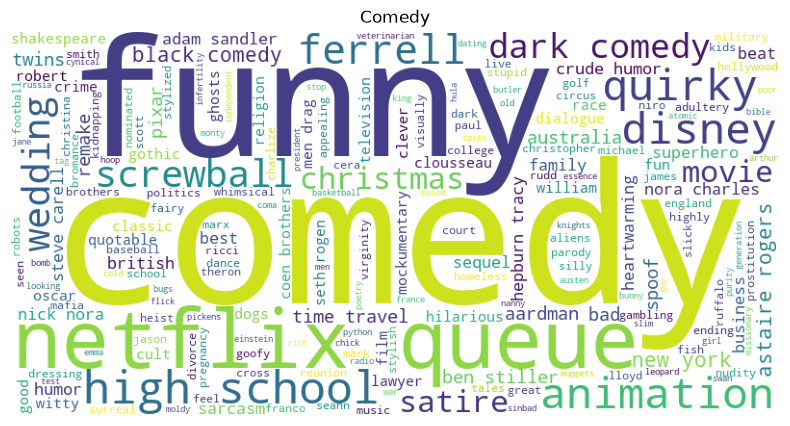

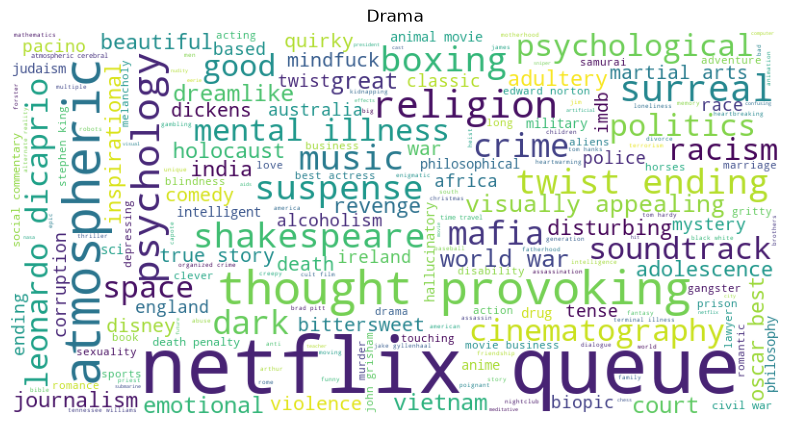

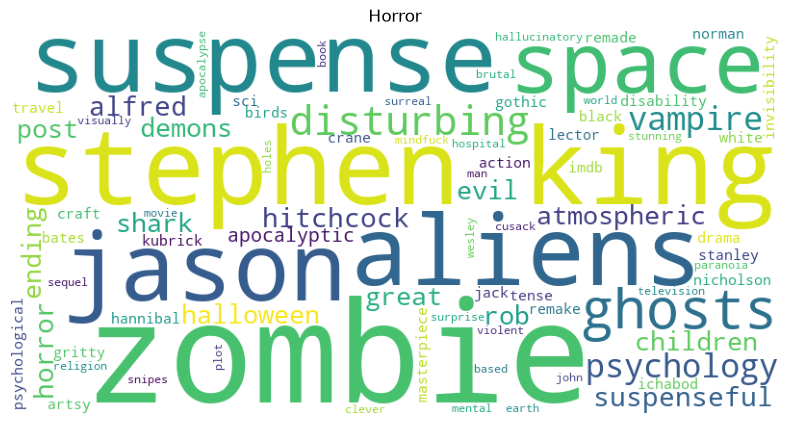

In [18]:
for genre in chosen:
    text = ' '.join(data[data['label'] == genre]['clean_text'])
    cloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(cloud)
    plt.axis('off')
    plt.title(genre)
    plt.show()

##### WordCloud: характерні слова кожного жанру

У WordCloud розмір слова пропорційний частоті його вживання в усіх текстах класу, а часті словосполучення (на кшталт «dark comedy», «high school», «thought provoking») виділяються автоматично.

1. Comedy. Найбільші слова: `funny`, `comedy`, `dark comedy`, `satire`, `quirky`, `high school`, а також імена коміків і студій (Ferrell, Ben Stiller, Adam Sandler, Pixar, Disney, Aardman) та піджанри (`screwball`, `spoof`, `animation`). Лексика чітко пов'язана з гумором.
2. Drama. Слова серйозніші й різноманітніші: `atmospheric`, `thought provoking`, `psychology`, `religion`, `politics`, `racism`, `mafia`, `world war`, `mental illness`, `twist ending`, `boxing`, `Shakespeare`. Це теми й настрій, а не одна чітка ознака, тому цей клас «розмитий».
3. Horror. Виразні слова: `zombie`, `suspense`, `stephen king`, `aliens`, `ghosts`, `vampire`, `jason`, `disturbing`, `halloween`, `hitchcock`. Це найчіткіший за лексикою жанр, але він найменший (52 фільми), тому слова в хмарі підкріплені лише кількома прикладами й вона менш надійна.
4. Слова `netflix queue` великі в Drama та Comedy: це службовий тег користувачів («у моїй черзі на перегляд»), а не ознака жанру. Тобто висока частота слова не означає, що воно інформативне для класу. TF-IDF (див. нижче) частково компенсує це, зменшуючи вагу слів, які трапляються в багатьох документах.
5. Деякі слова є прямою підказкою жанру (`comedy`, `funny`, `horror`), а інші (`psychology`, `atmospheric`) трапляються одразу в кількох класах, що ускладнює класифікацію.

In [19]:
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    data['clean_text'], data['label'], test_size=0.3, random_state=10, stratify=data['label'])

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(739, 962)
(317, 962)


##### Векторизація: TF-IDF

Модель працює з числами, тому тексти перетворено на вектори за допомогою `TfidfVectorizer`. Вага слова в документі дорівнює добутку TF (частота слова в документі) та IDF (обернена частота документів: чим рідше слово трапляється в усьому корпусі, тим більша його вага). Тому характерні, але нечасті слова (`zombie`, `satire`) отримують більшу вагу, ніж слова, що зустрічаються майже скрізь. Порядок слів не враховується (модель «мішка слів», Лекція 5).

Вибірку розбито на навчальну та тестову у співвідношенні 70/30 (739 і 317 документів) зі стратифікацією за класом. Словник і ваги IDF формуються (`fit_transform`) лише за навчальними текстами, а до тестових застосовується лише `transform`, щоб тест залишався незалежним. Результат: розріджені матриці 739 × 962 і 317 × 962, де 962 є розміром словника. Кожен документ містить лише кілька слів, тому майже всі значення матриці дорівнюють нулю.

In [20]:
params = {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0]}
grid = GridSearchCV(MultinomialNB(), params, cv=5, scoring='f1_macro')
grid.fit(X_train_tfidf, y_train_text)

print('Найкращий alpha:', grid.best_params_)
print('F1 macro на крос-валідації:', grid.best_score_)

Найкращий alpha: {'alpha': 0.1}
F1 macro на крос-валідації: 0.5213766090645575


##### Модель класифікації та підбір гіперпараметра

Використано Multinomial Naive Bayes (Лекції 3 і 5): класичний класифікатор для текстів (приклад зі спам-фільтром у Лекції 5). За теоремою Баєса він обчислює ймовірність кожного класу за словами документа, припускаючи (наївно), що слова незалежні за умови класу. Він швидкий, добре працює з розрідженими векторами великої розмірності й не потребує багато даних, що важливо для 739 навчальних документів.

Гіперпараметр `alpha` це згладжування Лапласа: слову, якого не було в документах класу, надається мала ненульова ймовірність замість 0 (інакше таке слово «обнулило» б ймовірність класу). Малий `alpha` майже не згладжує, а великий надто розмиває відмінності між класами. Перебиралися значення {0.01, 0.05, 0.1, 0.5, 1.0} за допомогою `GridSearchCV` із 5-кратною крос-валідацією лише на навчальній вибірці. Як метрику обрано `f1_macro`, бо класи незбалансовані: accuracy «винагороджувала» б модель за вгадування лише великого класу Drama.

Найкращий результат дав `alpha = 0.1` (macro-F1 на крос-валідації 0.52). Оптимальне значення лежить усередині сітки, тому розширювати її не потрібно.

In [21]:
model = grid.best_estimator_
y_pred_text = model.predict(X_test_tfidf)

print(classification_report(y_test_text, y_pred_text))
print(model.classes_)
print(confusion_matrix(y_test_text, y_pred_text))
print(y_test_text.value_counts(normalize=True))

              precision    recall  f1-score   support

      Comedy       0.78      0.51      0.61        99
       Drama       0.77      0.93      0.84       203
      Horror       0.75      0.40      0.52        15

    accuracy                           0.77       317
   macro avg       0.77      0.61      0.66       317
weighted avg       0.77      0.77      0.76       317

['Comedy' 'Drama' 'Horror']
[[ 50  48   1]
 [ 13 189   1]
 [  1   8   6]]
label
Drama     0.640379
Comedy    0.312303
Horror    0.047319
Name: proportion, dtype: float64


##### Оцінювання якості

Результати на тестовій вибірці (317 документів):

| Клас | Precision | Recall | F1 | Документів |
|---|---|---|---|---|
| Comedy | 0.78 | 0.51 | 0.61 | 99 |
| Drama | 0.77 | 0.93 | 0.84 | 203 |
| Horror | 0.75 | 0.40 | 0.52 | 15 |
| Accuracy | | | 0.77 | 317 |
| Macro avg | 0.77 | 0.61 | 0.66 | 317 |

Матриця помилок (рядки: справжній клас, стовпці: передбачений, порядок Comedy, Drama, Horror): `[[50, 48, 1], [13, 189, 1], [1, 8, 6]]`.

Метрики: precision це частка правильних серед усіх документів, які модель віднесла до класу; recall це частка знайдених документів класу з усіх справжніх; F1 це їх гармонічне середнє; macro avg усереднює метрики за класами незалежно від їхнього розміру.

Інтерпретація:

1. Accuracy 0.77 (245 правильних із 317) краща за тривіальну модель, яка завжди відповідає «Drama» (частка Drama в тесті 0.64). Але macro-F1 лише 0.66, тобто якість нерівномірна за класами.
2. Drama розпізнається найкраще (recall 0.93): це найбільший клас, і модель частіше схиляється саме до нього.
3. Comedy має низький recall (0.51): 48 із 99 комедій модель назвала драмами. Класи Comedy і Drama перетинаються за лексикою (службовий тег `netflix queue` та інші загальні слова трапляються в обох), а в кожному документі лише кілька слів.
4. Horror: precision 0.75 за recall 0.40. Модель знайшла лише 6 із 15 фільмів жахів, але коли вона називає Horror, то здебільшого правильно (6 із 8). Це наслідок малого класу (близько 36 прикладів у навчальній вибірці). На тесті лише 15 документів, тому один фільм змінює recall приблизно на 6.7 в.п., і метрики для Horror нестабільні.
5. Macro-F1 на крос-валідації (0.52) нижча, ніж на тесті (0.66). Імовірно, це пояснюється шумом через малий клас: у кожній перевірочній частині крос-валідації лише близько 7 документів Horror, тому оцінка для цього класу сильно коливається.
6. Помірна якість закономірна: документи дуже короткі (1–3 слова), жанри перетинаються, даних небагато, а теги суб'єктивні.

##### Висновки

1. PCA. Кількість ознак зменшено з 87 до 60 (на 31%) зі збереженням 95.1% дисперсії. Якість Random Forest трохи знизилась (accuracy 0.961 → 0.943), а час навчання зріс приблизно в 3.6 раза (0.46 → 1.66 с), оскільки компоненти PCA є неперервними й дереву доводиться перебирати більше порогів. Для цих даних PCA як крок підготовки перед Random Forest недоцільна, вона більше підходить для візуалізації та лінійних моделей.
2. t-SNE. На 2D-карті легітимні та фішингові сайти займають різні області, але в центрі є зона перемішування, а окремі фішингові групи лежать усередині «легітимної» області. Це узгоджується з високою, але не ідеальною точністю класифікації (понад 96%).
3. K-Means. За Elbow Method виразного «ліктя» немає (inertia знижується плавно), а silhouette найвищий для K=2 (0.33). Знайдені кластери не відповідають справжнім класам: ARI = 0.056. Окремий кластер утворили лише 24.1% фішингових сайтів (найбільш «нетипові»), а решта потрапила разом з легітимними. Кластер і клас не одне й те саме: K-Means групує за схожістю ознак, а не за міткою.
4. Тексти. Для класифікації жанру за тегами (Comedy, Drama, Horror) використано очищення тексту, TF-IDF і Multinomial Naive Bayes із `alpha = 0.1`. Отримано accuracy 0.77 і macro-F1 0.66 (тривіальна модель дає accuracy 0.64). Модель добре розпізнає Drama (F1 0.84), гірше Comedy (0.61) та Horror (0.52). Основні причини помірної якості: дуже короткі тексти, перетин жанрів, малий клас Horror і суб'єктивність тегів.

Усі результати відтворюються при `random_state=10`; час навчання залежить від комп'ютера.